In [1]:
import json
from datetime import timezone
from pathlib import Path
from typing import Dict, List, Optional, Tuple
from bisect import bisect_right  
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.dates as mdates
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize

import numpy as np

import sys, importlib
import obspy
from obspy import read, UTCDateTime, Stream
from obspy.core.util import AttribDict
from obspy.geodetics.base import gps2dist_azimuth
from obspy.imaging.cm import obspy_sequential
from obspy.signal.array_analysis import array_processing
from obspy.taup import TauPyModel
from obspy.geodetics import locations2degrees

In [2]:
# --- helpers ---
HELPERS_DIR = Path("/home/elizabeth/soft/src/QuickQuake/quickquake").resolve()
if str(HELPERS_DIR) not in sys.path:
    sys.path.insert(0, str(HELPERS_DIR))

import qq_helpers as h
importlib.reload(h)
print("helpers:", h.__file__)

# --- paths ---
DATA_ROOT = Path("/home/elizabeth/soft/src/QuickQuake/data").resolve()

CATALOG_CSV   = DATA_ROOT / "merged/output/GAMMA_hypodd_catalog.csv" #qq_Aniakchak_2023_buffer20km.csv   usgs_Aniakchak_2023_buffer20km.csv GAMMA_hypodd_catalog.csv
PICKS_CSV     = DATA_ROOT / "merged/input/GAMMA_picks_cleaned.csv"
STATIONS_JSON = DATA_ROOT / "merged/input/GAMMA_station_list.json"

INDEX_PATH = Path("/home/elizabeth/soft/src/QuickQuake/waveform_index.pkl").resolve()


helpers: /home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py


In [3]:
catalog_df, picks_df, stations_df = h.load_inputs(CATALOG_CSV, PICKS_CSV, STATIONS_JSON)
print("Loaded:", catalog_df.shape, picks_df.shape, stations_df.shape)

# Canonical column handles
catc = h.CatalogCols()
pkc  = h.PicksCols()
stc  = h.StationCols()

# Waveform index
if INDEX_PATH.exists():
    wf_index = h.WaveformIndex.load(INDEX_PATH)
else:
    wf_index = h.WaveformIndex.build([DATA_ROOT], glob_pattern="**/waveforms/*.mseed")
    wf_index.save(INDEX_PATH)

stream_cache = h.StreamCache()
print("Indexed mseed files:", len(wf_index.df))

print("Catalog time min/max:", catalog_df[catc.time].min(), catalog_df[catc.time].max())
print("Waveforms time min/max:",
      pd.to_datetime(wf_index.df["t0"], unit="s", utc=True).min(),
      pd.to_datetime(wf_index.df["t1"], unit="s", utc=True).max())


Loaded: (67, 6) (1271, 9) (11, 4)
Indexed mseed files: 2
Catalog time min/max: 2021-07-28 11:54:51.250000+00:00 2021-07-29 23:38:45.560000+00:00
Waveforms time min/max: 2021-07-29 08:00:00+00:00 2021-07-30 00:00:00+00:00


In [4]:
# check 
print("Catalog time min/max:", catalog_df["datetime"].min(), catalog_df["datetime"].max())
print("Waveforms time min/max:",
      pd.to_datetime(wf_index.df["t0"], unit="s", utc=True).min(),
      pd.to_datetime(wf_index.df["t1"], unit="s", utc=True).max())


Catalog time min/max: 2021-07-28 11:54:51.250000+00:00 2021-07-29 23:38:45.560000+00:00
Waveforms time min/max: 2021-07-29 08:00:00+00:00 2021-07-30 00:00:00+00:00


MOVEOUT PLOT

[moveout] No waveforms in window.
0 files: [] stations: 0
1 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 9
2 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
3 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
4 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 6
5 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 11
6 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 7
7 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
[moveout] No waveforms in window.
8 files: [] stations: 0
9 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 8
10 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
11 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 9
12 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations

/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:535: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=figsize)


26 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
27 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 6
28 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 11
29 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
30 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 11
[moveout] No waveforms in window.
31 files: [] stations: 0
32 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 7
33 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 7
34 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 10
35 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 11
36 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 8
37 files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed'] stations: 6
38 files: ['2021-07-29T08-00-00.mseed', '202

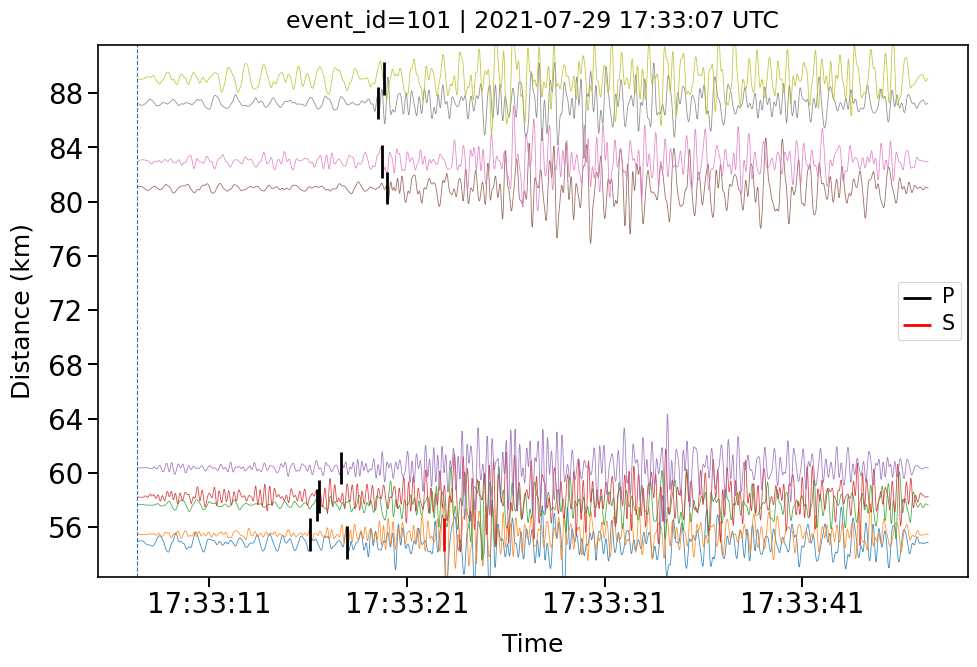

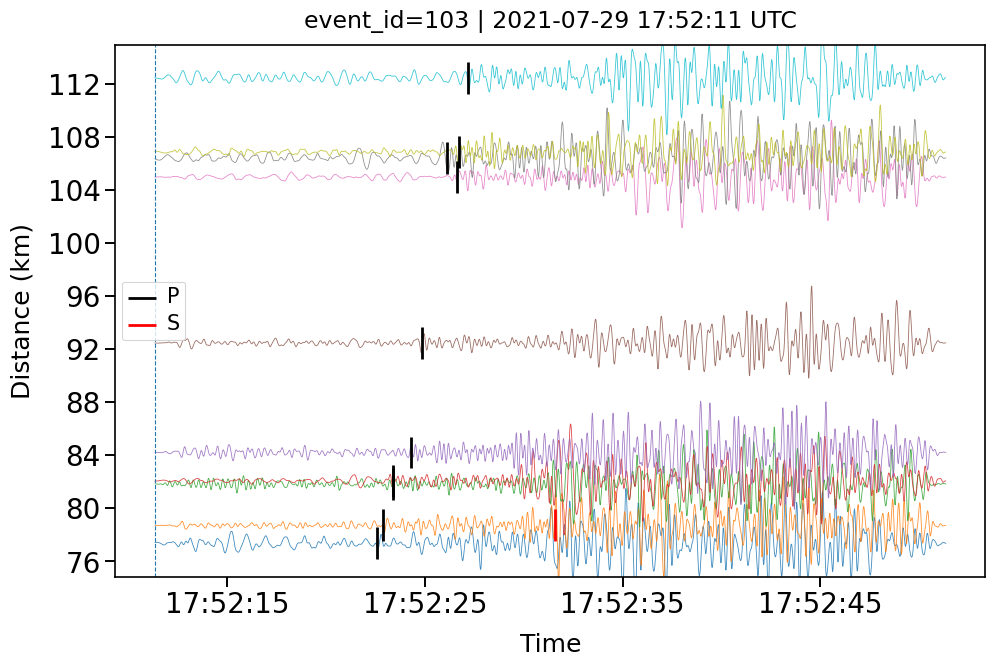

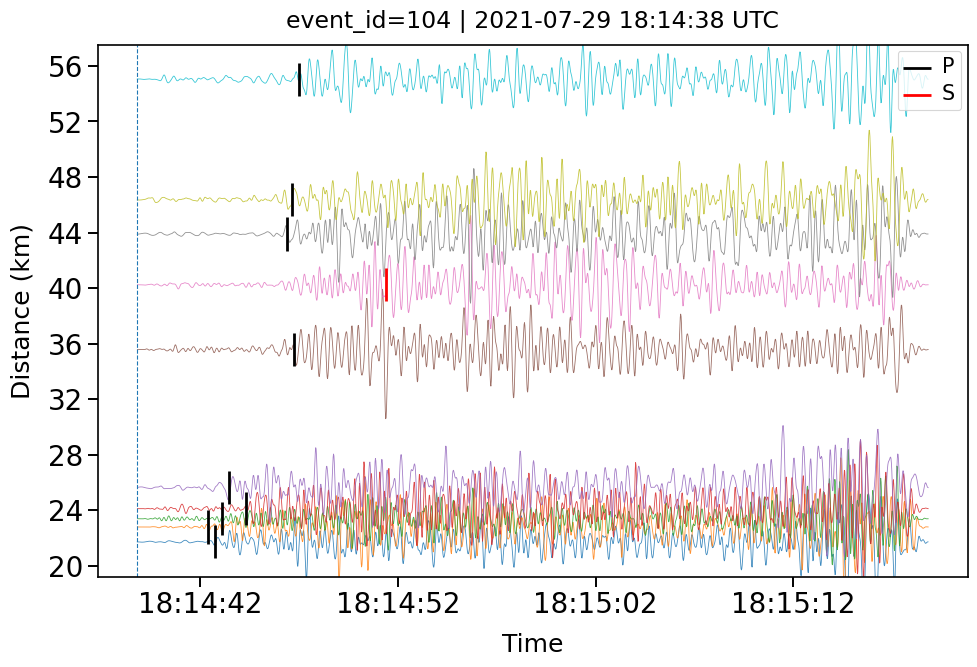

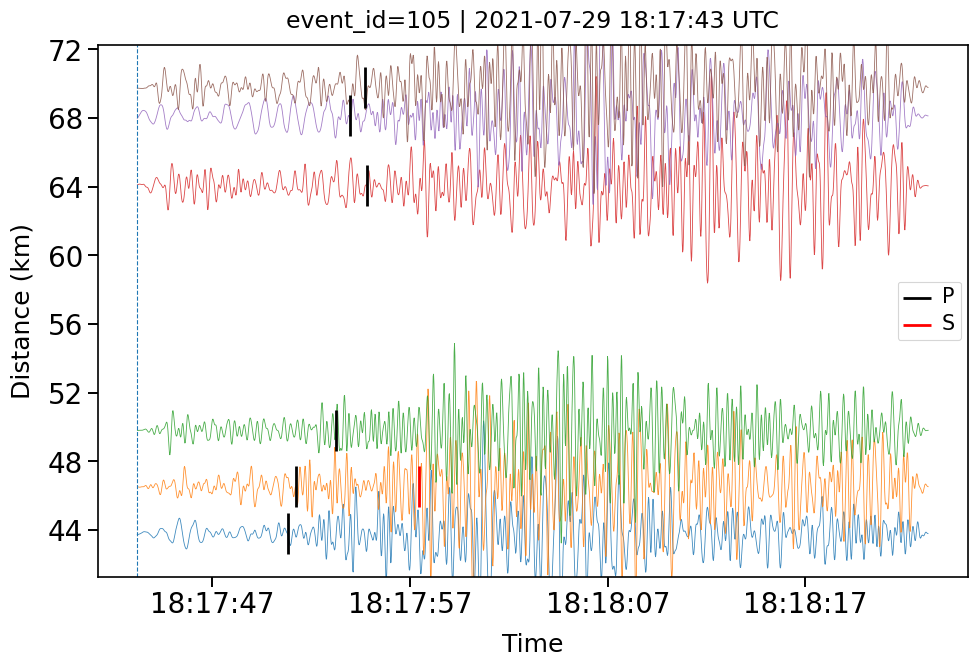

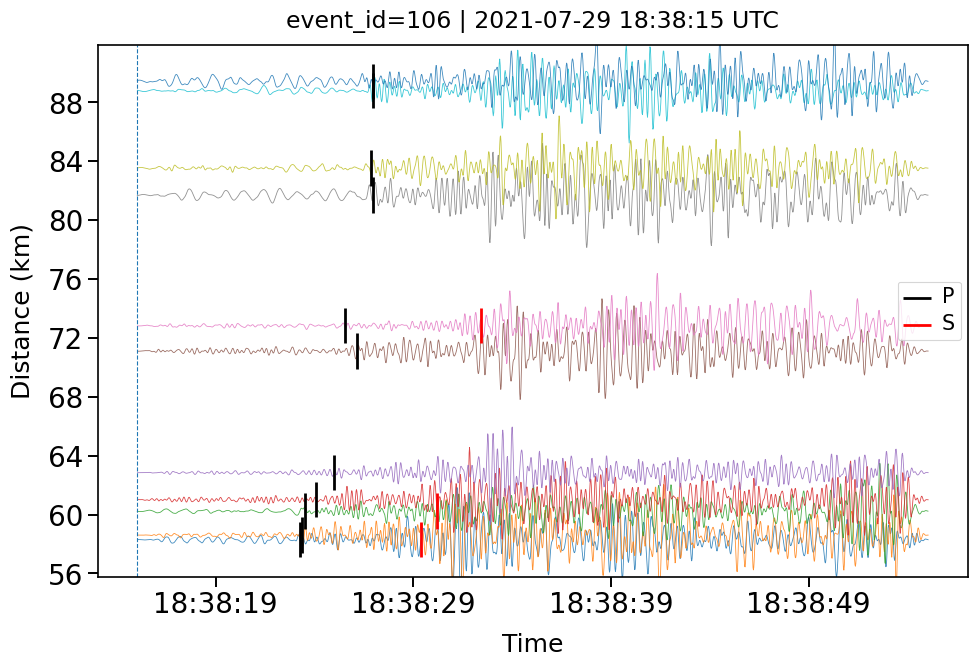

...

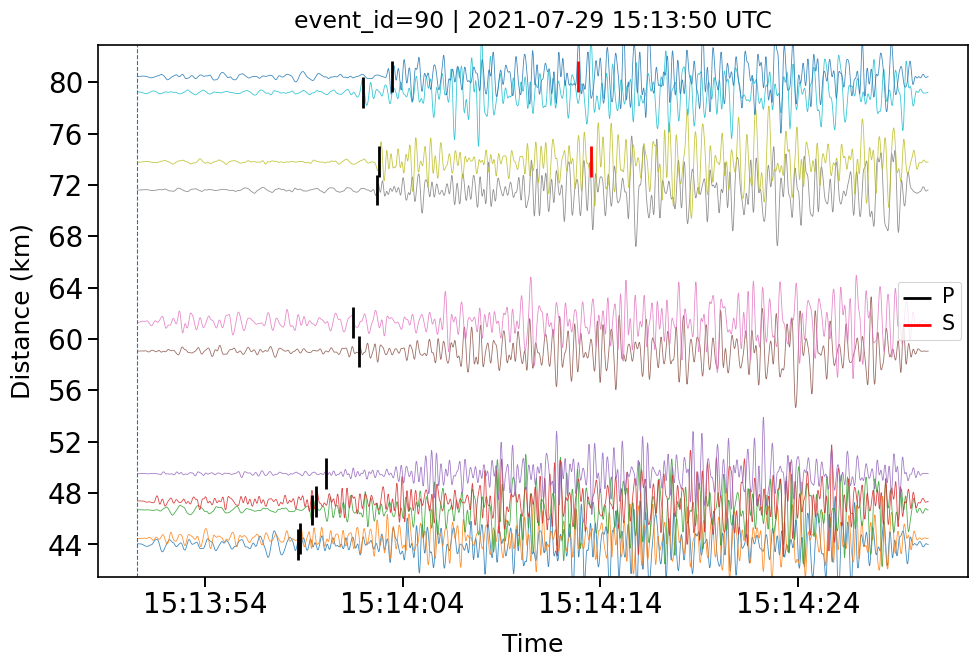

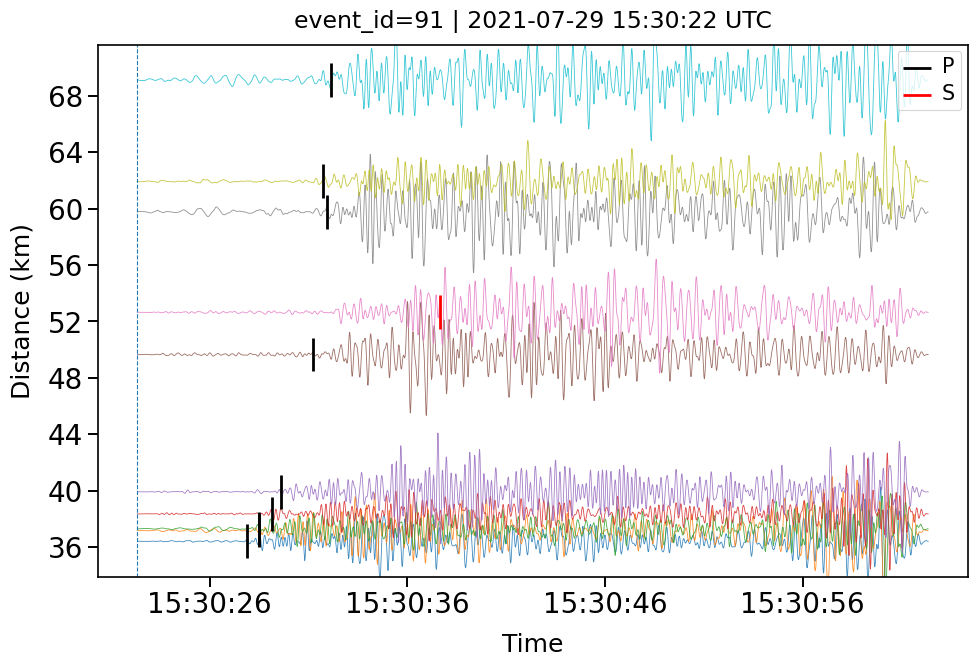

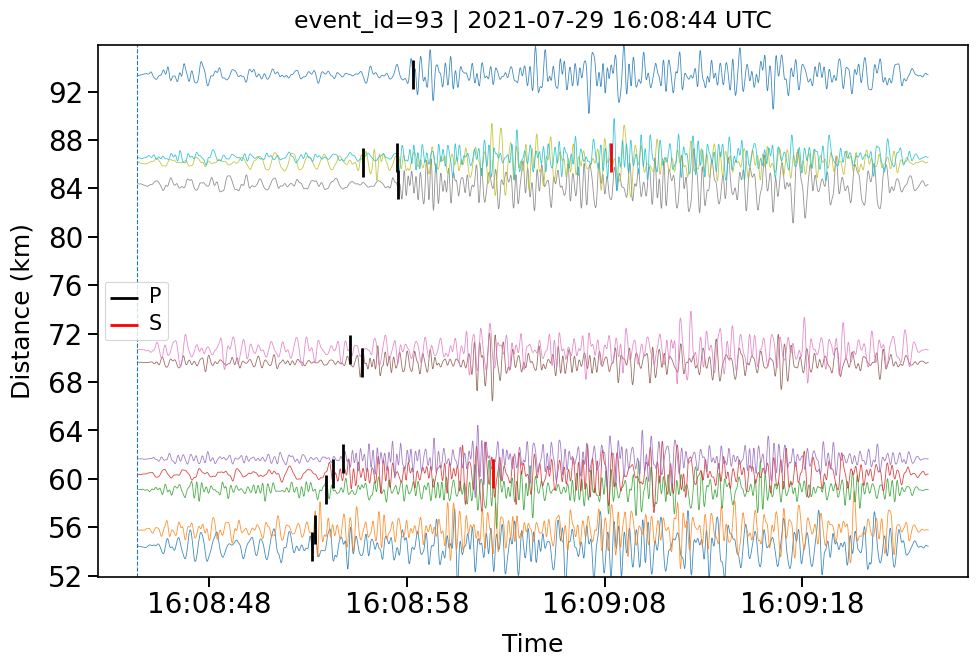

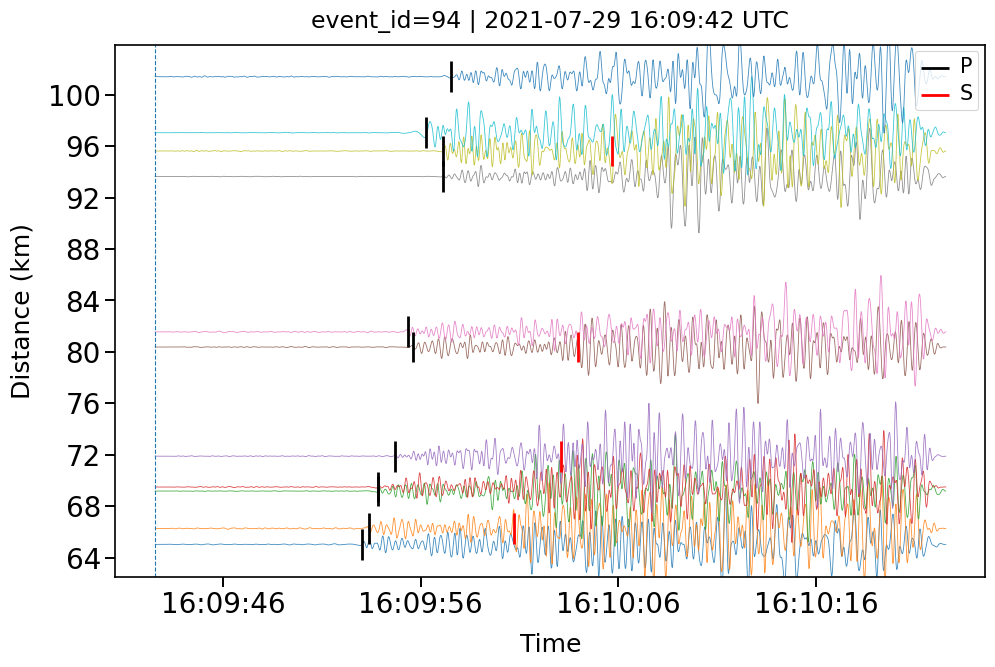

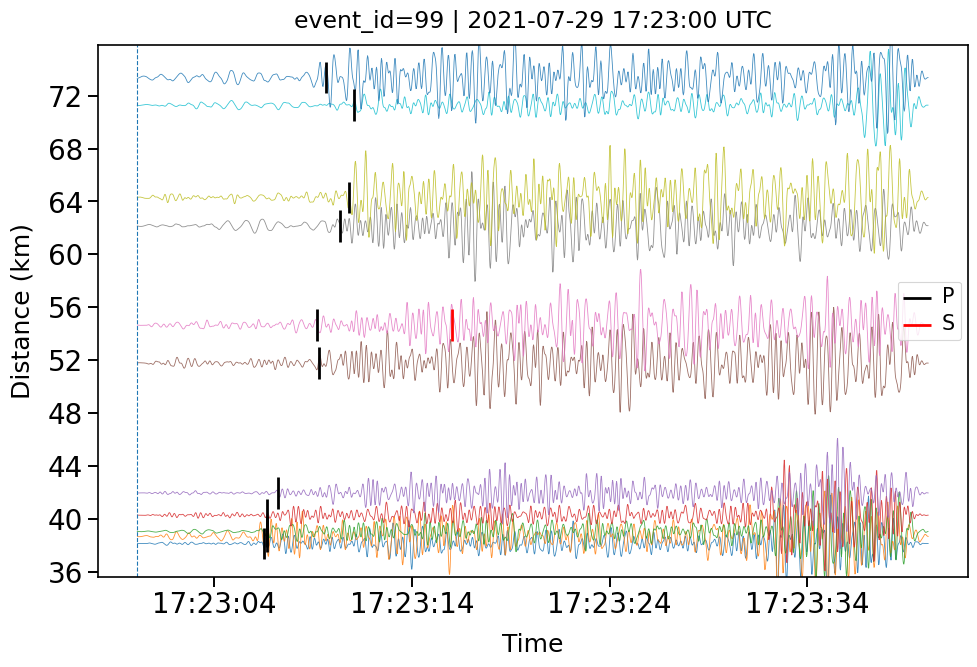

In [5]:
from pathlib import Path

for row_idx, row_event in catalog_df.iloc[0:70].iterrows():

    fig, ax, meta = h.plot_event_moveout_pretty(
        row_event=row_event,
        picks=picks_df,
        stations=stations_df,
        cache=stream_cache,
        wf_index=wf_index,

        # ventana
        pre_s=0,
        post_s=40,

        # filtro
        freqmin=1.0,
        freqmax=5.0,

        # tamaño de figura
        figsize=(10, 7),

        # separación/amplitud vertical
        wiggle_frac_of_spacing=2.0,
        y_pad_km=2.5,
        y_tick_step_km=4.0,

        # picks
        p_color="black",
        s_color="red",
        line_height_km=2.4,
        line_width=2.0,

        # letras
        label_fontsize=18,
        tick_fontsize=20,
        title_fontsize=17,
        legend_fontsize=15,

        # separación ticks eje x
        x_tick_seconds=10,

        # opcional guardar
        # save_path=f"moveout_event_{row_idx}.svg",
    )

    print(
        row_idx,
        "files:", [Path(f).name for f in meta["files"]],
        "stations:", len(meta["stations_used"])
    )

SPECTROGRAM

[spec] No waveforms in window.


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: []
stations used: 0


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 9


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 7


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])
/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10
[spec] No waveforms in window.
files: []
stations used: 0


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 8


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 9


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 7


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])
/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:770: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(
/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11
[spec] No waveforms in window.
files: []
stations used: 0
[spec] No waveforms in window.


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])
/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: []
stations used: 0
[spec] No waveforms in window.
files: []
stations used: 0
[spec] No waveforms in window.


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: []
stations used: 0


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 9


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11
[spec] No waveforms in window.


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: []
stations used: 0


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 7


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 7


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 11


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 8


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 6


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 9


/home/elizabeth/soft/src/QuickQuake/quickquake/qq_helpers.py:992: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.90, 0.98])


files: ['2021-07-29T08-00-00.mseed', '2021-07-29T16-00-00.mseed']
stations used: 10


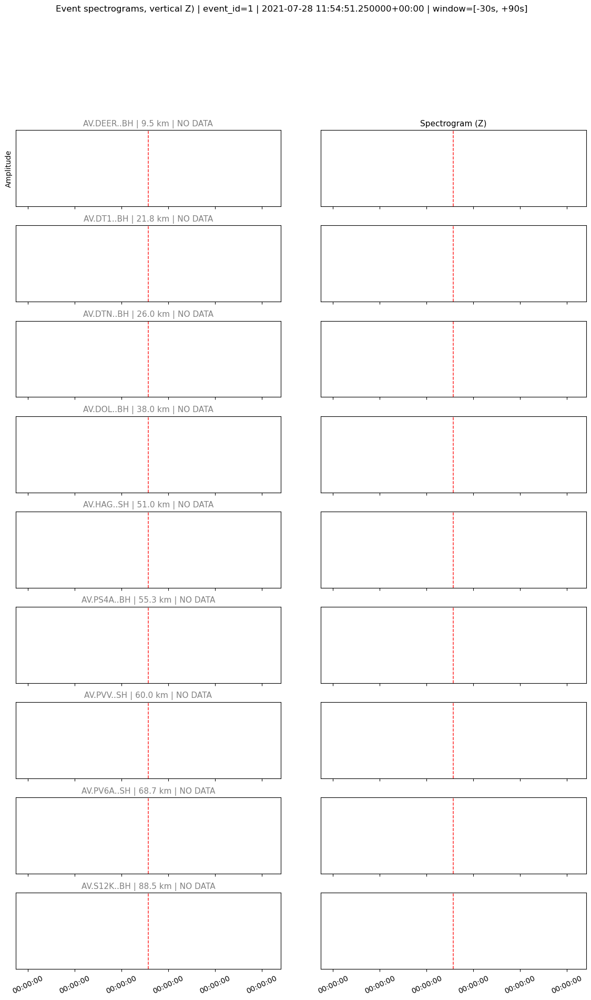

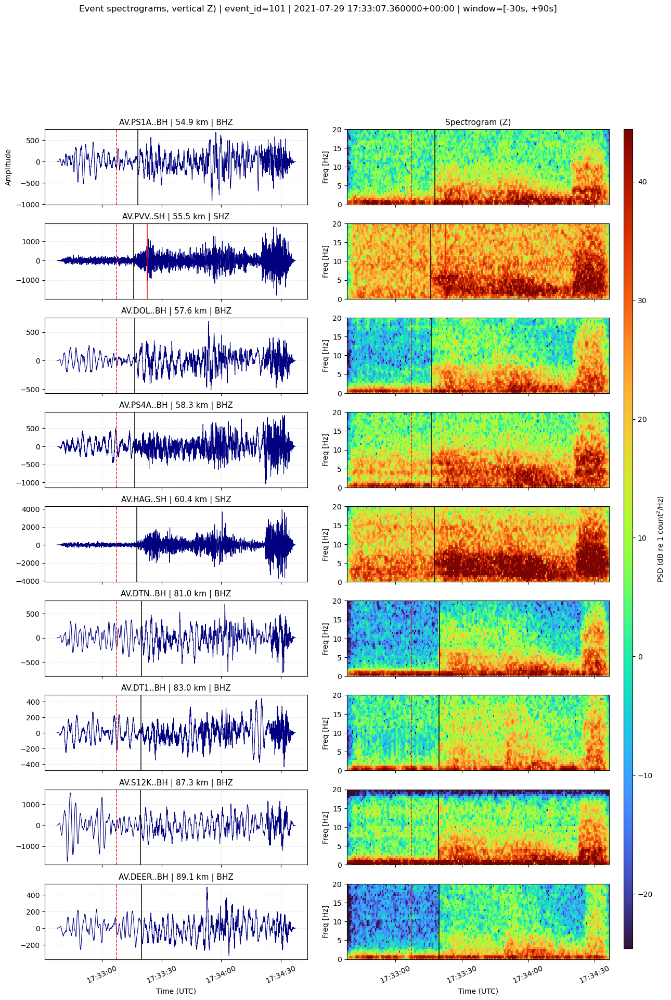

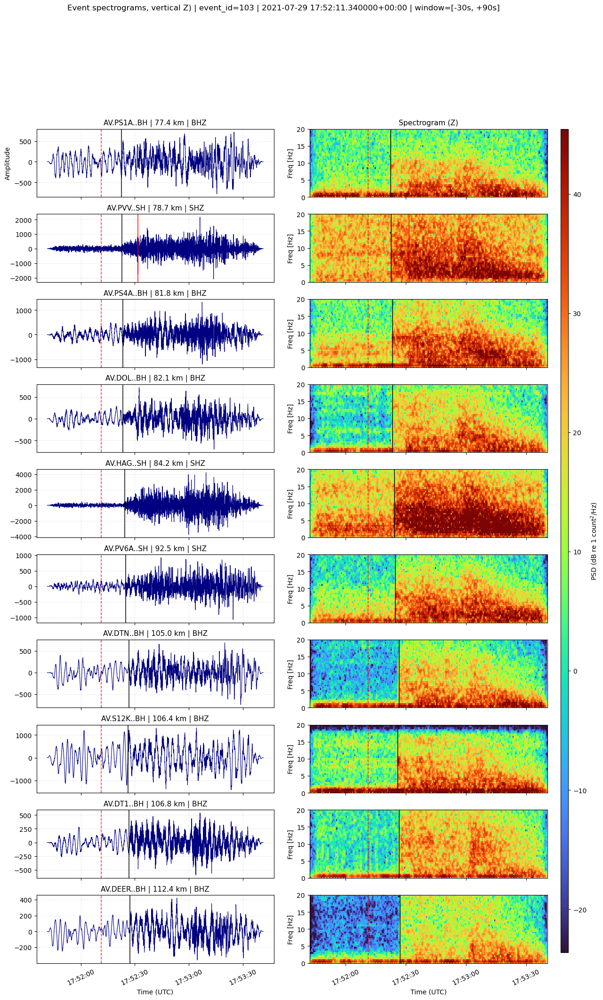

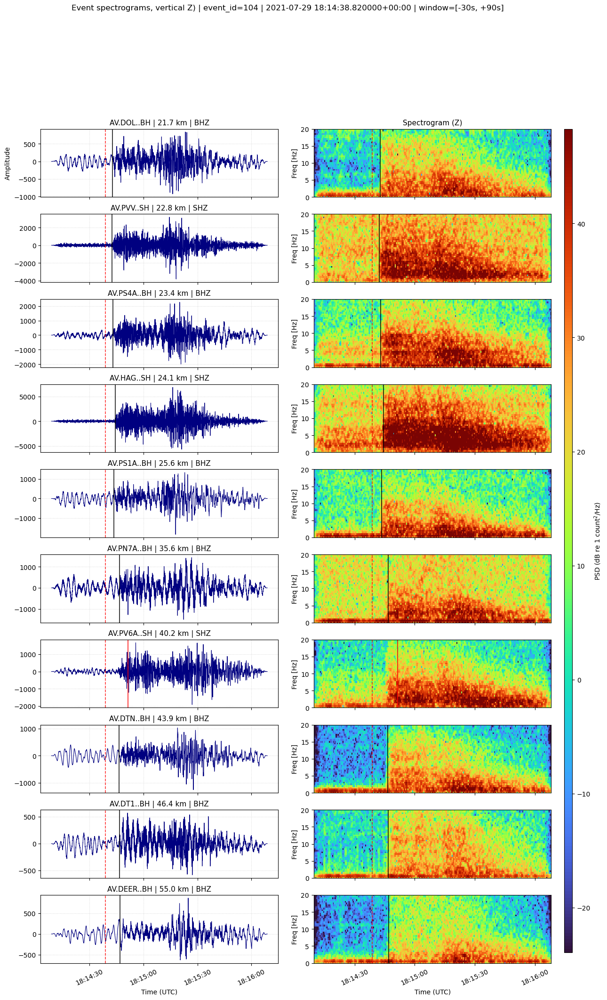

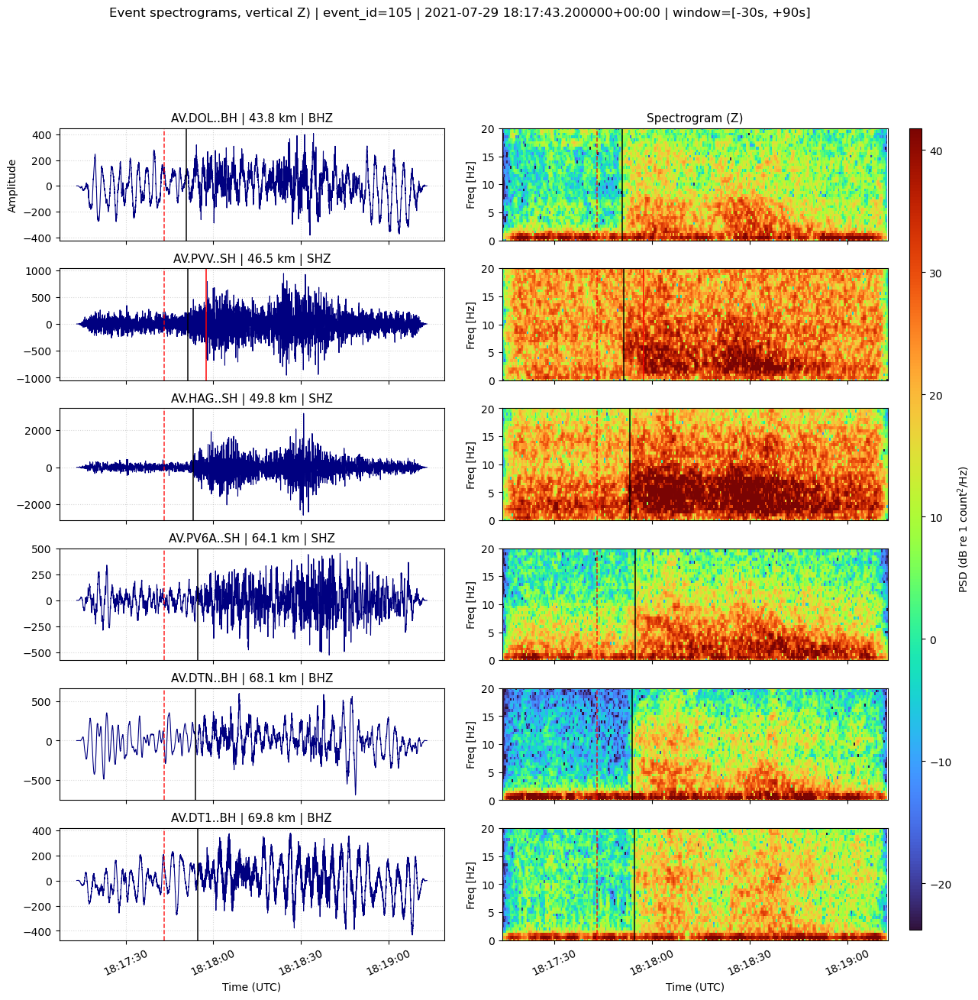

...

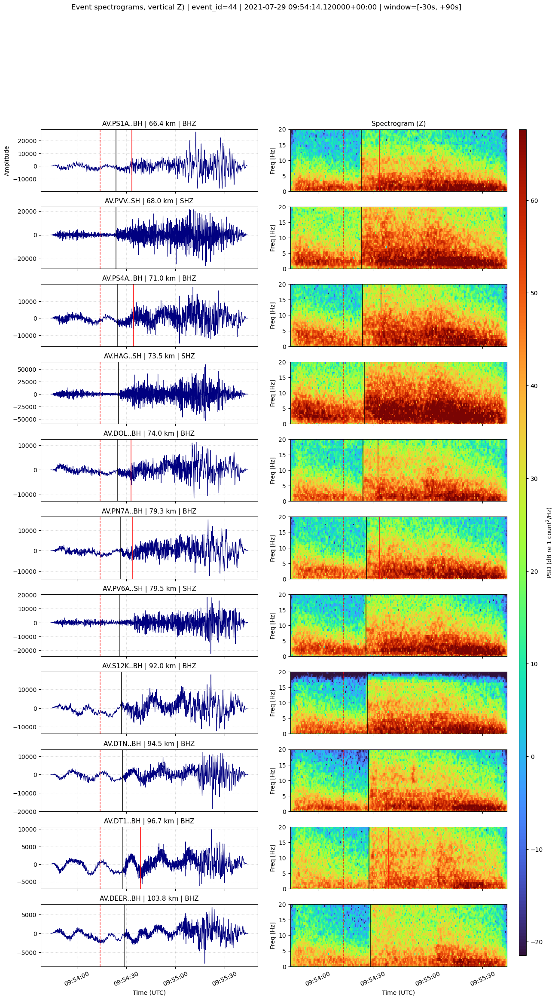

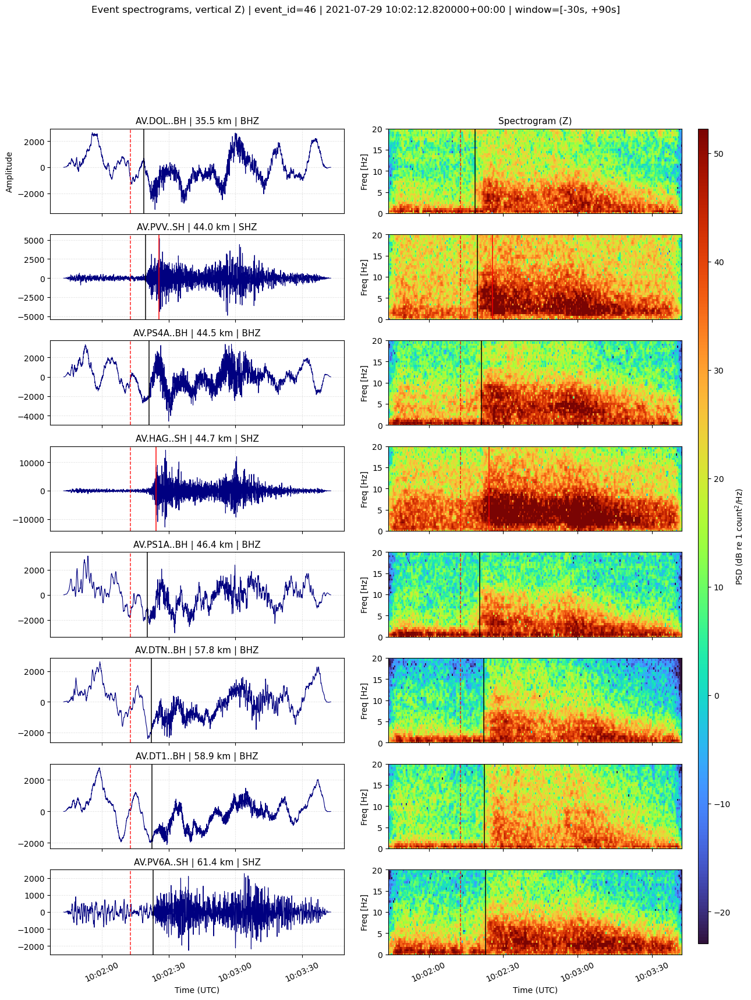

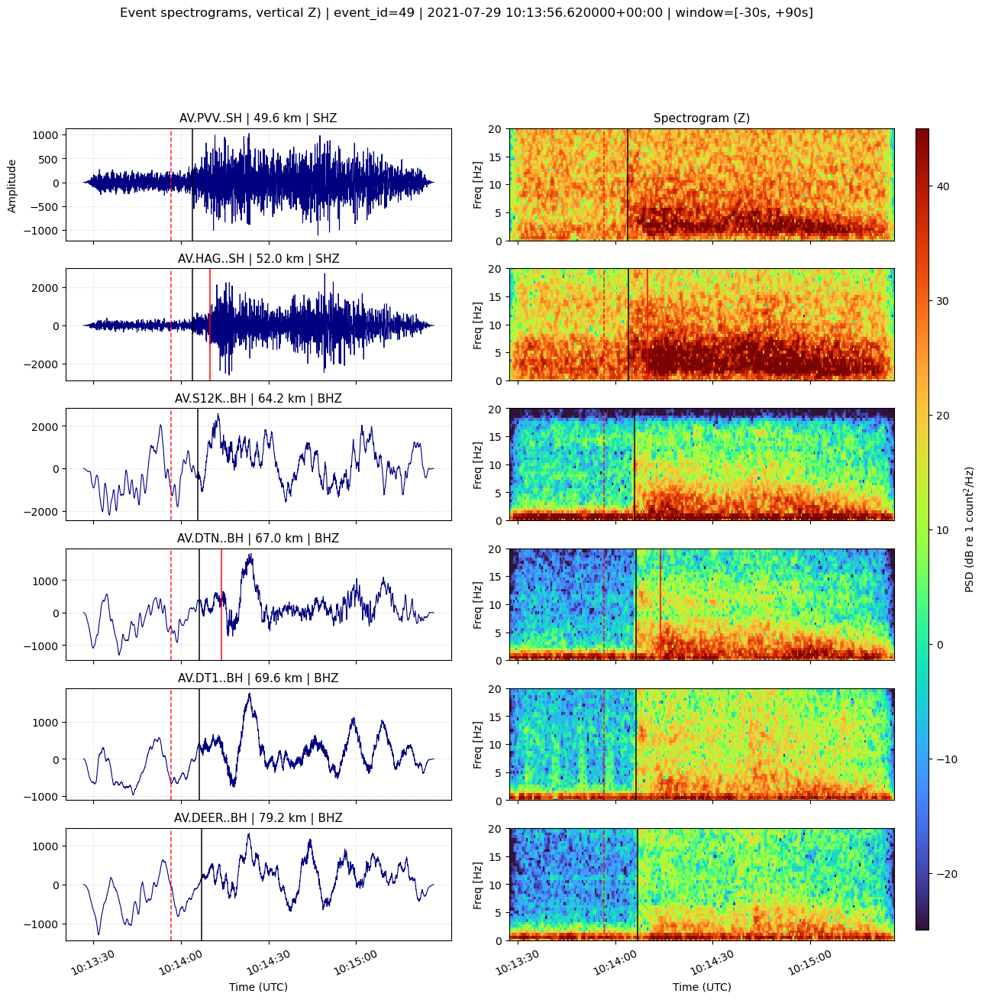

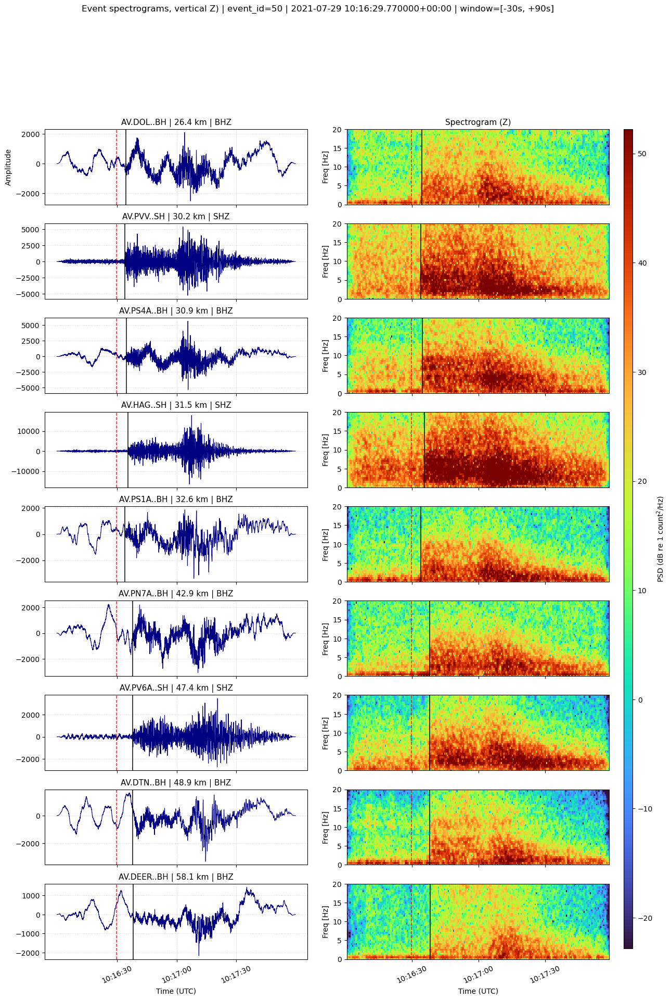

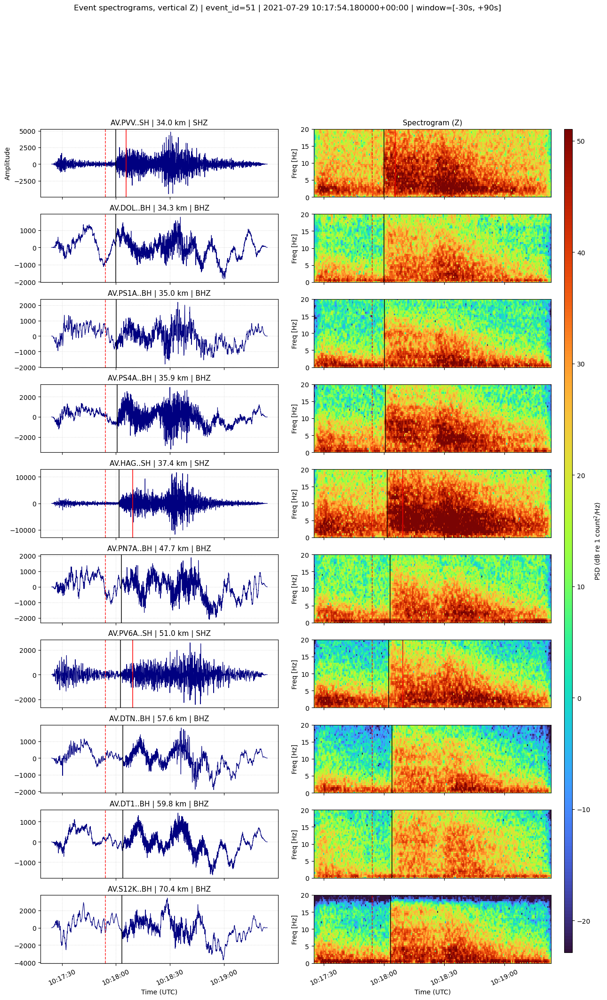

In [6]:
for row_idx, row_event in catalog_df.iloc[0:40].iterrows():
    fig, axes, meta = h.plot_event_spectrograms_vertical_picks_only(
        row_event=row_event,
        picks=picks_df,
        stations=stations_df,
        cache=stream_cache,
        wf_index=wf_index,
        pre_s=30,
        post_s=90,
        window_s=2,
        overlap_frac=0.8,
        freq_min=0,
        freq_max=20,
    )
    print("files:", [Path(f).name for f in meta["files"]])
    print("stations used:", len(meta["stations_used"]))


Pavlof seismicity map from 2020-01-01 to 2023-12-31 (Size = Magnitude | Color = Depth)


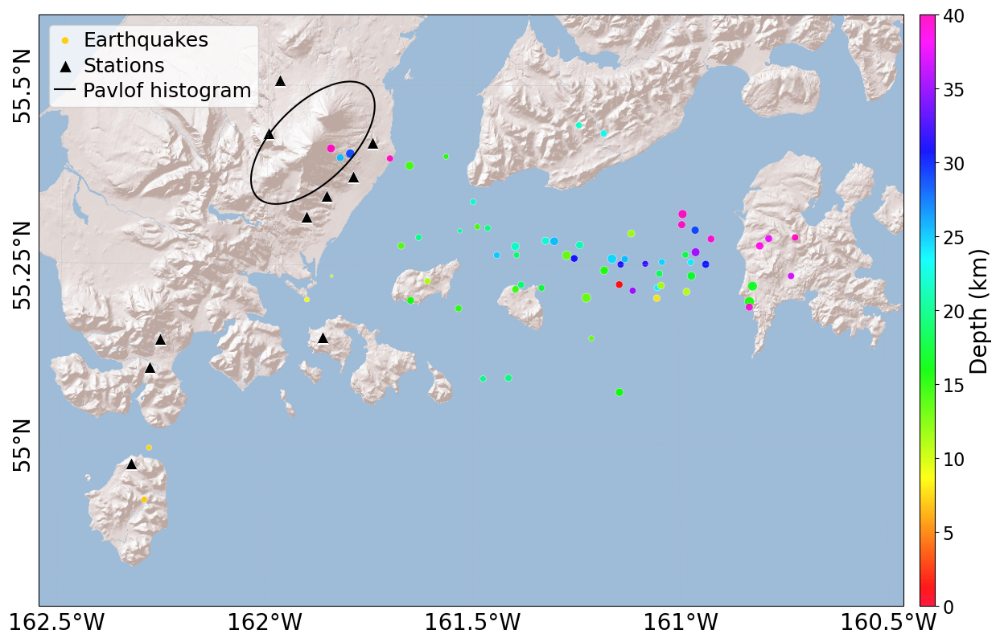

(<Figure size 1500x800 with 2 Axes>, <GeoAxes: >)

In [7]:
start_2021 = "2020-01-01T00:00:00Z"
end_2021   = "2023-12-31T23:59:59Z"

h.plot_mapview_seismicity(
    catalog=catalog_df,
    stations=stations_df,
    start=start_2021,
    end=end_2021,
    relief_zoom=12,
    savefig=False,
    ellipse_lon=-161.89, ellipse_lat=55.42,
    a_km=12, b_km=6, theta_deg=45,
)

In [8]:
import matplotlib.pyplot as plt
import qq_helpers as h

fig, ax, meta = h.plot_mapview3d_months(
    catalog=catalog_df,          # el mismo catálogo que vienes usando
    start="2021-01-01",
    end="2022-01-01",            # end exclusivo (como tu script)
    depth_max=40,
    exagg=4,
    view_elev=4,
    view_azim=34,
    dem_res="15s",
    savefig=False,               # no guarda por defecto
)

plt.show()
print("Number of plotted seismic events:", meta["n_events"])

ModuleNotFoundError: No module named 'pygmt'

In [ ]:
import plotly.io as pio
pio.renderers.default = "notebook_connected"   # o "vscode" si estás en VSCode

fig = h.plot_catalog_3d_topo_seismicity(
    catalog=catalog_df,
    mode="time",
    show=True,   
)



ModuleNotFoundError: No module named 'pygmt'

In [ ]:
fig = h.plot_catalog_3d_topo_seismicity(
    catalog=catalog_df,
    mode="year_month",
    year=2021,
    show=True,
)


ModuleNotFoundError: No module named 'pygmt'

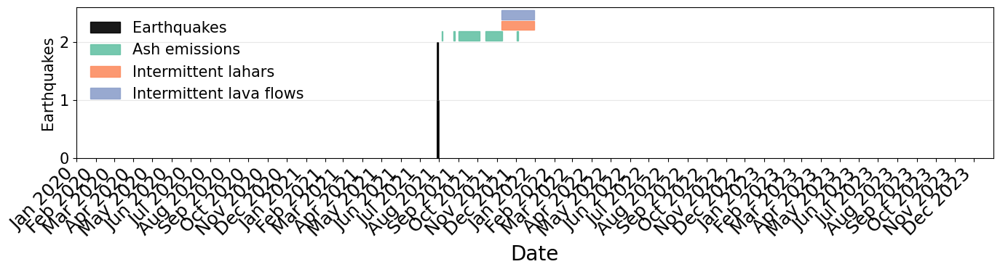

In [ ]:
# 1) El usuario edita esto (por región / por año / etc.)
event_spans = [
    ("2021-08-05", "2021-08-06", "Ash emissions"),
    ("2021-08-24", "2021-08-26", "Ash emissions"),
    ("2021-09-01", "2021-10-04", "Ash emissions"),
    ("2021-10-14", "2021-11-10", "Ash emissions"),
    ("2021-12-03", "2021-12-05", "Ash emissions"),
    ("2021-11-08", "2021-12-31", "Intermittent lahars"),
    ("2021-11-08", "2021-12-31", "Intermittent lava flows"),
]

# 2) 1 sola línea de plotting (NO guarda png por defecto)
fig, ax, meta = h.plot_timeline_histogram(
    catalog=catalog_df,         # o dataquake si usas el CSV de elipse
    start=start_2021,
    end=end_2021,
    spans=event_spans,
    n_bins=90,
    savefig=False,              # <-- clave: no guardar a menos que tú lo pidas
)
plt.show()